# Evidencia de aprendizaje 1 – Análisis y herramientas de extracción de datos
**Web scraping con BeautifulSoup: iPhone 18 Pro y iPhone 18 Pro Max en iShop Colombia**

- **Estudiante:** Camilo Londoño
- **Institución:** Institución Universitaria Digital de Antioquia (IU Digital)
- **Sitio analizado:** [co.tiendasishop.com](https://co.tiendasishop.com) – colección *iPhone 18 Pro y 18 Pro Max*
- **Herramienta:** `requests` + `BeautifulSoup` (Python)

**Objetivo:** aplicar la metodología de scraping para extraer el catálogo completo de variantes (modelo, capacidad y color) del iPhone 18 Pro y 18 Pro Max, con su SKU, precio y disponibilidad, y analizar cómo varía el precio según esas características.

> Proyecto con fines educativos. Se respeta el `robots.txt` del sitio (solo se consultan páginas de colección y de producto, sin parámetros de consulta, carrito ni checkout) y se hace una pausa entre peticiones para no saturar el servidor.

## 1. Librerías y configuración

In [ ]:
import re
import json
import time

import requests
from bs4 import BeautifulSoup
import pandas as pd
import matplotlib.pyplot as plt

# URL base del comercio y colección a analizar
BASE_URL = 'https://co.tiendasishop.com'
URL_COLECCION = BASE_URL + '/collections/iphone-18-pro-y-18-pro-max'

# Encabezados de la petición HTTP (simulan un navegador)
headers = {
    'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 '
                  '(KHTML, like Gecko) Chrome/115.0.0.0 Safari/537.36',
    'Accept-Language': 'es-CO,es;q=0.9',
}

PAUSA_SEGUNDOS = 1.5     # pausa entre peticiones (buenas prácticas)
VARIANTES_ESPERADAS = 32 # 2 modelos x 4 capacidades x 4 colores

sesion = requests.Session()
sesion.headers.update(headers)

## 2. Función para hacer la petición y crear el objeto BeautifulSoup

In [ ]:
def obtener_soup(url, intentos=3):
    """Hace la petición HTTP y devuelve (soup, status_code). Reintenta si falla."""
    ultimo_status = None
    for intento in range(1, intentos + 1):
        try:
            response = sesion.get(url, timeout=30)
            ultimo_status = response.status_code
            if response.status_code == 200:
                return BeautifulSoup(response.text, 'html.parser'), 200
            print(f'Petición fallida ({response.status_code}) intento {intento}: {url}')
        except requests.RequestException as e:
            print(f'Error de conexión intento {intento}: {e}')
        time.sleep(PAUSA_SEGUNDOS * intento)
    return None, ultimo_status

## 3. Petición a la colección iPhone 18 Pro y 18 Pro Max
Se descarga el HTML de la colección y se buscan los enlaces a las fichas de producto (`<a href="/products/...">`).

In [ ]:
soup_coleccion, status = obtener_soup(URL_COLECCION)

if soup_coleccion:
    print('Petición exitosa:', status)
    print('Título de la página:', soup_coleccion.title.get_text(strip=True) if soup_coleccion.title else '-')
else:
    raise SystemExit(f'No se pudo descargar la colección (status {status})')

# Enlaces a productos. Los href vienen con espacios y saltos de línea: se limpian con strip()
enlaces_coleccion = set()
for a in soup_coleccion.select('a[href*="/products/"]'):
    href = a['href'].strip().split('?')[0]
    if '/products/iphone-18-pro-' in href:
        enlaces_coleccion.add(href)

print(f'Fichas iPhone 18 Pro encontradas en la colección: {len(enlaces_coleccion)}')
for e in sorted(enlaces_coleccion):
    print(' -', e)

Petición exitosa: 200
Título de la página: Nuevo iPhone 18 Pro y 18 Pro Max - Elige tu favorito | iShop Colombia
Fichas iPhone 18 Pro encontradas en la colección: 2
 - /products/iphone-18-pro-mjrt4lz-a
 - /products/iphone-18-pro-mjxq4lz-a


## 4. Descubrir todas las variantes (modelo × capacidad × color)
Cada combinación de modelo, capacidad y color es una URL distinta en iShop. El HTML de una ficha contiene los *handles* de todas las variantes en los selectores de opciones, así que se extraen con una expresión regular.

El patrón exige que el handle empiece exactamente por `iphone-18-pro-` y termine en `4lz-a`, para descartar accesorios como las fundas (`funda-...-para-el-iphone-18-pro-...4zm-a`).

In [ ]:
PATRON_HANDLE = re.compile(r'(?<![a-z0-9-])iphone-18-pro-m[a-z0-9]{3}4lz-a')

handles = set()
for enlace in sorted(enlaces_coleccion):
    soup_ficha, status = obtener_soup(BASE_URL + enlace)
    if soup_ficha:
        handles.update(PATRON_HANDLE.findall(str(soup_ficha)))
    time.sleep(PAUSA_SEGUNDOS)
    if len(handles) >= VARIANTES_ESPERADAS:
        break

urls_variantes = sorted(f'{BASE_URL}/products/{h}' for h in handles)
print(f'Variantes encontradas: {len(urls_variantes)} (esperadas: {VARIANTES_ESPERADAS})')

Variantes encontradas: 32 (esperadas: 32)


## 5. Extracción de los datos de cada variante
De cada ficha se leen los **datos estructurados JSON-LD** (`<script type="application/ld+json">`, tipo `Product`), que traen nombre, SKU, marca, precio, moneda y disponibilidad. Si no existieran, se usa el `<h1>` como respaldo.

El modelo, la capacidad y el color se obtienen del nombre del producto (por ejemplo, *iPhone 18 Pro Max 256 GB Borgoña*).

In [ ]:
DISPONIBILIDAD = {'InStock': 'Disponible', 'OutOfStock': 'Agotado',
                  'PreOrder': 'Preventa', 'LimitedAvailability': 'Pocas unidades'}


def buscar_producto_jsonld(soup):
    """Devuelve el diccionario JSON-LD de tipo Product, o None."""
    for script in soup.find_all('script', type='application/ld+json'):
        try:
            datos = json.loads(script.string or script.get_text())
        except (json.JSONDecodeError, TypeError):
            continue
        candidatos = datos if isinstance(datos, list) else datos.get('@graph', [datos])
        for item in candidatos:
            if isinstance(item, dict) and item.get('@type') == 'Product':
                return item
    return None


def separar_caracteristicas(nombre):
    """'iPhone 18 Pro Max 256 GB Borgoña' -> ('iPhone 18 Pro Max', '256 GB', 'Borgoña')"""
    m = re.search(r'^(.*?)\s+(\d+\s*(?:GB|TB))\s*(.*)$', nombre, flags=re.I)
    if not m:
        return nombre, 'No disponible', 'No disponible'
    modelo, capacidad, color = m.groups()
    return modelo.strip(), capacidad.upper().replace('  ', ' '), color.strip() or 'No disponible'


def extraer_producto(url):
    soup, status = obtener_soup(url)
    if not soup:
        return None, status

    producto = buscar_producto_jsonld(soup)
    if producto:
        nombre = producto.get('name', 'No disponible')
        sku = producto.get('sku', 'No disponible')
        marca = producto.get('brand', {})
        marca = marca.get('name', 'Apple') if isinstance(marca, dict) else (marca or 'Apple')
        ofertas = producto.get('offers', {})
        if isinstance(ofertas, list):
            ofertas = ofertas[0] if ofertas else {}
        precio = ofertas.get('price') or ofertas.get('lowPrice')
        moneda = ofertas.get('priceCurrency', 'COP')
        disponibilidad = str(ofertas.get('availability', '')).split('/')[-1]
    else:
        # Respaldo: leer el título visible de la página
        h1 = soup.find('h1')
        nombre = h1.get_text(strip=True).split('|')[0].strip() if h1 else 'No disponible'
        sku, marca, precio, moneda, disponibilidad = 'No disponible', 'Apple', None, 'COP', ''

    modelo, capacidad, color = separar_caracteristicas(nombre)
    precio = float(precio) if precio not in (None, '') else None

    return {
        'Referencia (SKU)': sku,
        'Nombre/Marca': f'[{marca}] {nombre}',
        'Valores': f"${precio:,.0f} {moneda}".replace(',', '.') if precio else 'No disponible',
        'Caracteristicas': f'{modelo} | {capacidad} | {color}',
        'Modelo': modelo,
        'Capacidad': capacidad,
        'Color': color,
        'Precio_COP': precio,
        'Disponibilidad': DISPONIBILIDAD.get(disponibilidad, disponibilidad or 'No disponible'),
        'URL': url,
        'Fuente': 'JSON-LD' if producto else 'HTML',
    }, status

In [ ]:
productos_lista = []
errores = []
inicio = time.time()

for i, url in enumerate(urls_variantes, start=1):
    fila, status = extraer_producto(url)
    if fila:
        productos_lista.append(fila)
        print(f"[{i:02d}/{len(urls_variantes)}] OK  {fila['Nombre/Marca']} -> {fila['Valores']}")
    else:
        errores.append({'URL': url, 'status': status})
        print(f'[{i:02d}/{len(urls_variantes)}] ERROR {status} {url}')
    time.sleep(PAUSA_SEGUNDOS)

duracion = time.time() - inicio
print(f'\nTerminado en {duracion:.1f} s. Productos: {len(productos_lista)} | Errores: {len(errores)}')

[01/32] OK  [Apple] iPhone 18 Pro 256 GB Negro -> $5.699.000 COP
[02/32] OK  [Apple] iPhone 18 Pro 256 GB Plata -> $5.699.000 COP
[03/32] OK  [Apple] iPhone 18 Pro 256 GB Borgoña -> $5.699.000 COP
[04/32] OK  [Apple] iPhone 18 Pro 256 GB Glaciar -> $5.699.000 COP
[05/32] OK  [Apple] iPhone 18 Pro 512 GB Negro -> $6.599.000 COP
[06/32] OK  [Apple] iPhone 18 Pro 512 GB Plata -> $6.599.000 COP
[07/32] OK  [Apple] iPhone 18 Pro 512 GB Borgoña -> $6.599.000 COP
[08/32] OK  [Apple] iPhone 18 Pro 512 GB Glaciar -> $6.599.000 COP
[09/32] OK  [Apple] iPhone 18 Pro 1 TB Negro -> $8.399.000 COP
[10/32] OK  [Apple] iPhone 18 Pro 1 TB Plata -> $8.399.000 COP
[11/32] OK  [Apple] iPhone 18 Pro 1 TB Borgoña -> $8.399.000 COP
[12/32] OK  [Apple] iPhone 18 Pro 1 TB Glaciar -> $8.399.000 COP
[13/32] OK  [Apple] iPhone 18 Pro 2 TB Negro -> $11.149.000 COP
[14/32] OK  [Apple] iPhone 18 Pro 2 TB Plata -> $11.149.000 COP
[15/32] OK  [Apple] iPhone 18 Pro 2 TB Borgoña -> $11.149.000 COP
[16/32] OK  [Apple] iP

## 6. DataFrame final

In [ ]:
def orden_capacidad(cap):
    m = re.match(r'(\d+)\s*(GB|TB)', str(cap))
    if not m:
        return 0
    return int(m.group(1)) * (1024 if m.group(2) == 'TB' else 1)

df_producto = pd.DataFrame(productos_lista)
df_producto = df_producto.drop_duplicates(subset=['URL'])
df_producto['orden_cap'] = df_producto['Capacidad'].map(orden_capacidad)
df_producto = (df_producto.sort_values(['Modelo', 'orden_cap', 'Color'])
                          .drop(columns='orden_cap')
                          .reset_index(drop=True))

display(df_producto[['Referencia (SKU)', 'Nombre/Marca', 'Valores', 'Caracteristicas', 'Disponibilidad']])

,Referencia (SKU),Nombre/Marca,Valores,Caracteristicas,Disponibilidad
0,MJRR4LZ/A,[Apple] iPhone 18 Pro 256 GB Borgoña,$5.699.000 COP,iPhone 18 Pro | 256 GB | Borgoña,Disponible
1,MJRT4LZ/A,[Apple] iPhone 18 Pro 256 GB Glaciar,$5.699.000 COP,iPhone 18 Pro | 256 GB | Glaciar,Disponible
2,MJRP4LZ/A,[Apple] iPhone 18 Pro 256 GB Negro,$5.699.000 COP,iPhone 18 Pro | 256 GB | Negro,Disponible
3,MJRQ4LZ/A,[Apple] iPhone 18 Pro 256 GB Plata,$5.699.000 COP,iPhone 18 Pro | 256 GB | Plata,Disponible
4,MJRW4LZ/A,[Apple] iPhone 18 Pro 512 GB Borgoña,$6.599.000 COP,iPhone 18 Pro | 512 GB | Borgoña,Disponible
5,MJRX4LZ/A,[Apple] iPhone 18 Pro 512 GB Glaciar,$6.599.000 COP,iPhone 18 Pro | 512 GB | Glaciar,Disponible
6,MJRU4LZ/A,[Apple] iPhone 18 Pro 512 GB Negro,$6.599.000 COP,iPhone 18 Pro | 512 GB | Negro,Disponible
7,MJRV4LZ/A,[Apple] iPhone 18 Pro 512 GB Plata,$6.599.000 COP,iPhone 18 Pro | 512 GB | Plata,Disponible
8,MJT14LZ/A,[Apple] iPhone 18 Pro 1 TB Borgoña,$8.399.000 COP,iPhone 18 Pro | 1 TB | Borgoña,Disponible
9,MJT24LZ/A,[Apple] iPhone 18 Pro 1 TB Glaciar,$8.399.000 COP,iPhone 18 Pro | 1 TB | Glaciar,Disponible


## 7. Métricas de éxito del scraping

In [ ]:
campos = ['Referencia (SKU)', 'Modelo', 'Capacidad', 'Color', 'Precio_COP', 'Disponibilidad']
completitud = (df_producto[campos].replace('No disponible', pd.NA).notna().mean() * 100).round(1)

metricas = pd.DataFrame({
    'Métrica': ['Variantes esperadas', 'Variantes extraídas', 'Cobertura (%)',
                'Peticiones con error', 'Registros leídos desde JSON-LD',
                'Tiempo total (s)', 'Completitud promedio de campos (%)'],
    'Valor': [VARIANTES_ESPERADAS, len(df_producto),
              round(len(df_producto) / VARIANTES_ESPERADAS * 100, 1),
              len(errores), int((df_producto['Fuente'] == 'JSON-LD').sum()),
              round(duracion, 1), round(completitud.mean(), 1)],
})
display(metricas)
print('Completitud por campo (%):')
display(completitud.to_frame('Completitud %'))

,Métrica,Valor
0,Variantes esperadas,32.0
1,Variantes extraídas,32.0
2,Cobertura (%),100.0
3,Peticiones con error,0.0
4,Registros leídos desde JSON-LD,32.0
5,Tiempo total (s),73.3
6,Completitud promedio de campos (%),100.0


Completitud por campo (%):


,Completitud %
Referencia (SKU),100.0
Modelo,100.0
Capacidad,100.0
Color,100.0
Precio_COP,100.0
Disponibilidad,100.0


## 8. Análisis de los datos
### 8.1 Precio por modelo y capacidad

In [ ]:
caps = sorted(df_producto['Capacidad'].unique(), key=orden_capacidad)

tabla_precios = (df_producto.pivot_table(index='Capacidad', columns='Modelo',
                                         values='Precio_COP', aggfunc='mean')
                            .reindex(caps))
display(tabla_precios.style.format('${:,.0f}'))

# Diferencia de precio entre Pro Max y Pro para la misma capacidad
if {'iPhone 18 Pro', 'iPhone 18 Pro Max'} <= set(tabla_precios.columns):
    dif = (tabla_precios['iPhone 18 Pro Max'] - tabla_precios['iPhone 18 Pro']).to_frame('Pro Max - Pro (COP)')
    display(dif.style.format('${:,.0f}'))

# Incremento de precio al subir de capacidad
incremento = tabla_precios.diff().dropna(how='all')
print('Incremento de precio al pasar a la siguiente capacidad (COP):')
display(incremento.style.format('${:,.0f}'))

# ¿El color cambia el precio?
print('Precios distintos por modelo y capacidad (1 = el color no cambia el precio):')
display(df_producto.groupby(['Modelo', 'Capacidad'])['Precio_COP'].nunique().unstack().reindex(columns=caps))

Modelo,iPhone 18 Pro,iPhone 18 Pro Max
Capacidad,,
256 GB,"$5,699,000","$6,199,000"
512 GB,"$6,599,000","$7,149,000"
1 TB,"$8,399,000","$8,949,000"
2 TB,"$11,149,000","$11,699,000"


,Pro Max - Pro (COP)
Capacidad,
256 GB,"$500,000"
512 GB,"$550,000"
1 TB,"$550,000"
2 TB,"$550,000"


Incremento de precio al pasar a la siguiente capacidad (COP):


Modelo,iPhone 18 Pro,iPhone 18 Pro Max
Capacidad,,
512 GB,"$900,000","$950,000"
1 TB,"$1,800,000","$1,800,000"
2 TB,"$2,750,000","$2,750,000"


Precios distintos por modelo y capacidad (1 = el color no cambia el precio):


Capacidad,256 GB,512 GB,1 TB,2 TB
Modelo,,,,
iPhone 18 Pro,1,1,1,1
iPhone 18 Pro Max,1,1,1,1


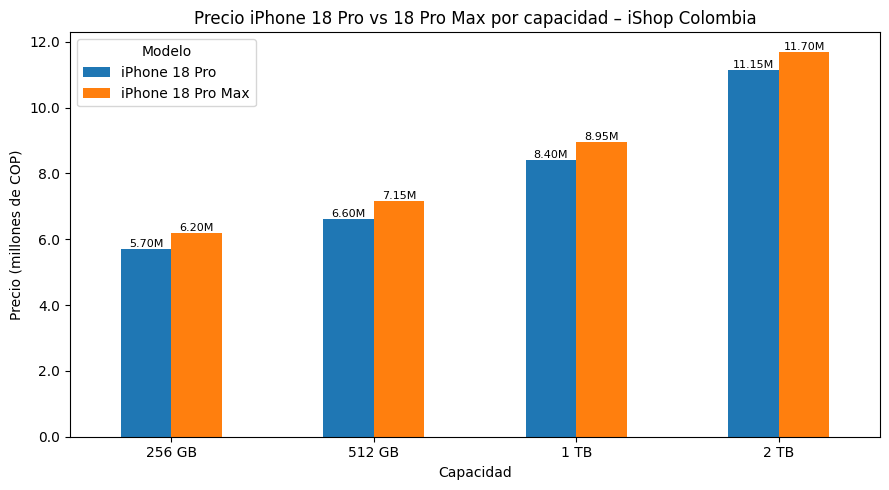

In [ ]:
ax = tabla_precios.plot(kind='bar', figsize=(9, 5), rot=0)
ax.set_title('Precio iPhone 18 Pro vs 18 Pro Max por capacidad – iShop Colombia')
ax.set_xlabel('Capacidad')
ax.set_ylabel('Precio (millones de COP)')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v/1e6:.1f}'))
for cont in ax.containers:
    ax.bar_label(cont, labels=[f'{v/1e6:.2f}M' if v == v else '' for v in cont.datavalues], fontsize=8)
plt.tight_layout()
plt.show()

### 8.2 Disponibilidad por modelo y color

Disponibilidad             Agotado  Disponible
Modelo            Color                       
iPhone 18 Pro     Borgoña        1           3
                  Glaciar        1           3
                  Negro          1           3
                  Plata          1           3
iPhone 18 Pro Max Borgoña        2           2
                  Glaciar        1           3
                  Negro          0           4
                  Plata          2           2

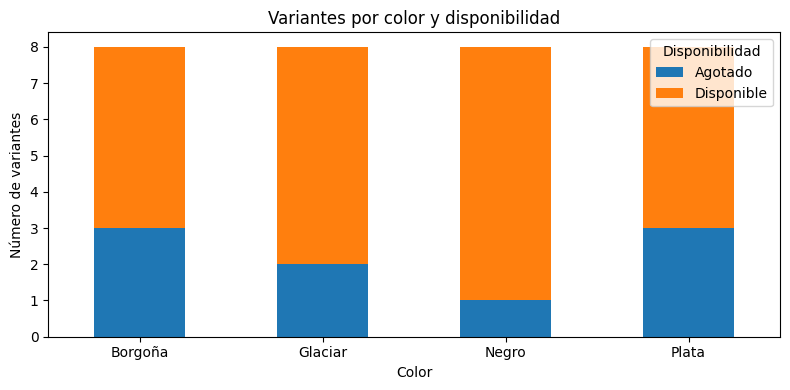

In [ ]:
disp = pd.crosstab([df_producto['Modelo'], df_producto['Color']], df_producto['Disponibilidad'])
display(disp)

ax = pd.crosstab(df_producto['Color'], df_producto['Disponibilidad']).plot(
    kind='bar', stacked=True, figsize=(8, 4), rot=0)
ax.set_title('Variantes por color y disponibilidad')
ax.set_ylabel('Número de variantes')
plt.tight_layout()
plt.show()

## 9. Exportar los resultados
El CSV queda disponible para las siguientes unidades del curso.

In [ ]:
nombre_csv = 'iphone18pro_ishop.csv'
df_producto.to_csv(nombre_csv, index=False, encoding='utf-8-sig')
print('Archivo guardado:', nombre_csv)

try:
    from google.colab import files  # solo funciona en Google Colab
    files.download(nombre_csv)
except ImportError:
    pass

Archivo guardado: iphone18pro_ishop.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Conclusiones
*(Completar después de ejecutar el notebook con los resultados obtenidos.)*

- **Funcionamiento del scraping:** ¿se extrajeron las 32 variantes? ¿Hubo errores?
- **Precio por capacidad:** ¿cuánto aumenta el precio al subir de capacidad?
- **Pro vs Pro Max:** ¿cuál es la diferencia de precio para una misma capacidad?
- **Color:** ¿el color influye en el precio o en la disponibilidad?
- **Metodología:** ventajas de leer los datos estructurados JSON-LD con BeautifulSoup frente a buscar clases CSS, y limitaciones (dependencia de la estructura del sitio, contenido cargado con JavaScript).